# Product Return Prediction – Machine Learning Pipeline

End-to-end workflow for predicting e-commerce product returns using an external dataset.
Includes schema validation, data cleaning, exploratory data analysis (EDA), automated feature engineering inside a `scikit-learn` pipeline, 5-fold cross-validation across multiple classifiers, validation-based threshold tuning, model persistence, and single/bulk inference templates.

## 1. Import Libraries & Configuration

In [8]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_PATH = Path("../data/ecommerce_returns.csv")
OUTPUT_DIR = Path("../models")
DATA_SOURCE = DATA_PATH.name

DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load External Dataset

Place your external CSV dataset at `../data/ecommerce_returns.csv` (or update `DATA_PATH` above).

**Expected Raw Columns:**
- `Order_ID` (identifier, excluded from modeling)
- `Product_Category`, `Payment_Method`, `Shipping_Type` (categorical)
- `Product_Price`, `Quantity`, `Discount_Percentage`, `Delivery_Days`, `Customer_Order_Count`, `Previous_Return_Count`, `Product_Rating` (numerical)
- `Returned` (binary target: `0` = Not Returned, `1` = Returned)

In [9]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH.resolve()}'. "
        "Please place your external CSV there or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded successfully from: {DATA_PATH}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Dataset loaded successfully from: ..\data\ecommerce_returns.csv
Shape: 7,000 rows x 12 columns


,Order_ID,Product_Category,Product_Price,Quantity,Discount_Percentage,Delivery_Days,Payment_Method,Customer_Order_Count,Previous_Return_Count,Product_Rating,Shipping_Type,Returned
0,IND-ORD-100001,Beauty & Personal Care,339.0,1,3.1,4,UPI,5,0,3.8,Standard,0
1,IND-ORD-100002,Electronics,1490.0,2,8.8,3,UPI,3,0,4.5,Express,0
2,IND-ORD-100003,Beauty & Personal Care,720.0,2,29.3,9,UPI,8,0,3.5,Standard,0
3,IND-ORD-100004,Home & Kitchen,1199.0,1,18.2,0,Credit Card,7,2,4.1,Same-Day,0
4,IND-ORD-100005,Fashion,249.0,1,10.5,2,UPI,6,0,4.2,Express,1


## 3. Data Inspection, Schema Validation & Cleaning

Validate required columns, drop duplicate orders, enforce domain rules, and prevent target leakage by excluding any post-return columns (e.g., `Return_Reason`, `Refund_Status`).

In [10]:
display(df.info())
display(df.describe(include="all").T)

missing_summary = df.isna().sum()
display(missing_summary[missing_summary > 0].to_frame("Missing_Count"))
print("Exact duplicate rows:", df.duplicated().sum())

RAW_REQUIRED_COLS = [
    "Order_ID",
    "Product_Category",
    "Product_Price",
    "Quantity",
    "Discount_Percentage",
    "Delivery_Days",
    "Payment_Method",
    "Customer_Order_Count",
    "Previous_Return_Count",
    "Product_Rating",
    "Shipping_Type",
    "Returned",
]

missing_cols = [c for c in RAW_REQUIRED_COLS if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns in external dataset: {missing_cols}")

# Drop exact duplicates and duplicate Order_IDs
df = df.drop_duplicates().drop_duplicates(subset=["Order_ID"]).copy()

# Enforce numeric types
NUMERIC_RAW_COLS = [
    "Product_Price",
    "Quantity",
    "Discount_Percentage",
    "Delivery_Days",
    "Customer_Order_Count",
    "Previous_Return_Count",
    "Product_Rating",
    "Returned",
]
for col in NUMERIC_RAW_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Clean target column
df = df.dropna(subset=["Returned"])
df = df[df["Returned"].isin([0, 1])].copy()
df["Returned"] = df["Returned"].astype(int)

# Apply domain validity constraints (invalid values become NaN for downstream imputation)
validation_rules = {
    "Product_Price": df["Product_Price"] >= 0,
    "Quantity": df["Quantity"] > 0,
    "Discount_Percentage": df["Discount_Percentage"].between(0, 100),
    "Delivery_Days": df["Delivery_Days"] >= 0,
    "Customer_Order_Count": df["Customer_Order_Count"] >= 0,
    "Previous_Return_Count": df["Previous_Return_Count"] >= 0,
    "Product_Rating": df["Product_Rating"].between(1, 5),
}
for col, valid_mask in validation_rules.items():
    invalid_count = (~valid_mask & df[col].notna()).sum()
    if invalid_count > 0:
        print(f"Flagged {invalid_count} out-of-range values in '{col}' as NaN.")
    df.loc[~valid_mask, col] = np.nan

# Logical consistency: prior returns cannot exceed prior orders
inconsistent_returns = df["Previous_Return_Count"] > df["Customer_Order_Count"]
if inconsistent_returns.sum() > 0:
    print(f"Flagged {inconsistent_returns.sum()} rows where Previous_Return_Count > Customer_Order_Count as NaN.")
    df.loc[inconsistent_returns, "Previous_Return_Count"] = np.nan

# Clean string categoricals
CATEGORICAL_RAW_COLS = ["Product_Category", "Payment_Method", "Shipping_Type"]
for col in CATEGORICAL_RAW_COLS:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .astype("object")
        .where(lambda values: values.notna(), np.nan)
    )
print(f"Cleaned dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_ID               7000 non-null   str    
 1   Product_Category       7000 non-null   str    
 2   Product_Price          7000 non-null   float64
 3   Quantity               7000 non-null   int64  
 4   Discount_Percentage    7000 non-null   float64
 5   Delivery_Days          7000 non-null   int64  
 6   Payment_Method         6930 non-null   str    
 7   Customer_Order_Count   7000 non-null   int64  
 8   Previous_Return_Count  7000 non-null   int64  
 9   Product_Rating         6825 non-null   float64
 10  Shipping_Type          6930 non-null   str    
 11  Returned               7000 non-null   int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 656.4 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,7000,7000,IND-ORD-100001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Category,7000,12,Fashion,2400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Price,7000.0,NaN,NaN,NaN,1884.390429,3063.142655,89.0,560.0,979.0,1880.0,47699.0
Quantity,7000.0,NaN,NaN,NaN,1.550714,0.920624,1.0,1.0,1.0,2.0,5.0
Discount_Percentage,7000.0,NaN,NaN,NaN,19.994486,11.414376,0.0,11.0,18.4,27.325,66.1
Delivery_Days,7000.0,NaN,NaN,NaN,5.651286,3.054391,0.0,3.0,6.0,8.0,14.0
Payment_Method,6930,6,UPI,2995,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Order_Count,7000.0,NaN,NaN,NaN,4.801571,4.459617,0.0,2.0,4.0,7.0,37.0
Previous_Return_Count,7000.0,NaN,NaN,NaN,0.718143,1.229193,0.0,0.0,0.0,1.0,21.0
Product_Rating,6825.0,NaN,NaN,NaN,3.906886,0.760177,1.0,3.5,4.1,4.5,5.0


,Missing_Count
Payment_Method,70
Product_Rating,175
Shipping_Type,70


Exact duplicate rows: 0
Cleaned dataset shape: 7,000 rows x 12 columns


,Order_ID,Product_Category,Product_Price,Quantity,Discount_Percentage,Delivery_Days,Payment_Method,Customer_Order_Count,Previous_Return_Count,Product_Rating,Shipping_Type,Returned
0,IND-ORD-100001,Beauty & Personal Care,339.0,1.0,3.1,4.0,UPI,5.0,0.0,3.8,Standard,0
1,IND-ORD-100002,Electronics,1490.0,2.0,8.8,3.0,UPI,3.0,0.0,4.5,Express,0
2,IND-ORD-100003,Beauty & Personal Care,720.0,2.0,29.3,9.0,UPI,8.0,0.0,3.5,Standard,0
3,IND-ORD-100004,Home & Kitchen,1199.0,1.0,18.2,0.0,Credit Card,7.0,2.0,4.1,Same-Day,0
4,IND-ORD-100005,Fashion,249.0,1.0,10.5,2.0,UPI,6.0,0.0,4.2,Express,1


## 4. Exploratory Data Analysis (EDA)

Examine class balance and how return rates vary across categories, delivery times, discounts, prices, and payment methods.

Overall Return Rate: 39.56%


Returned
Not Returned    4231
Returned        2769
Name: count, dtype: int64

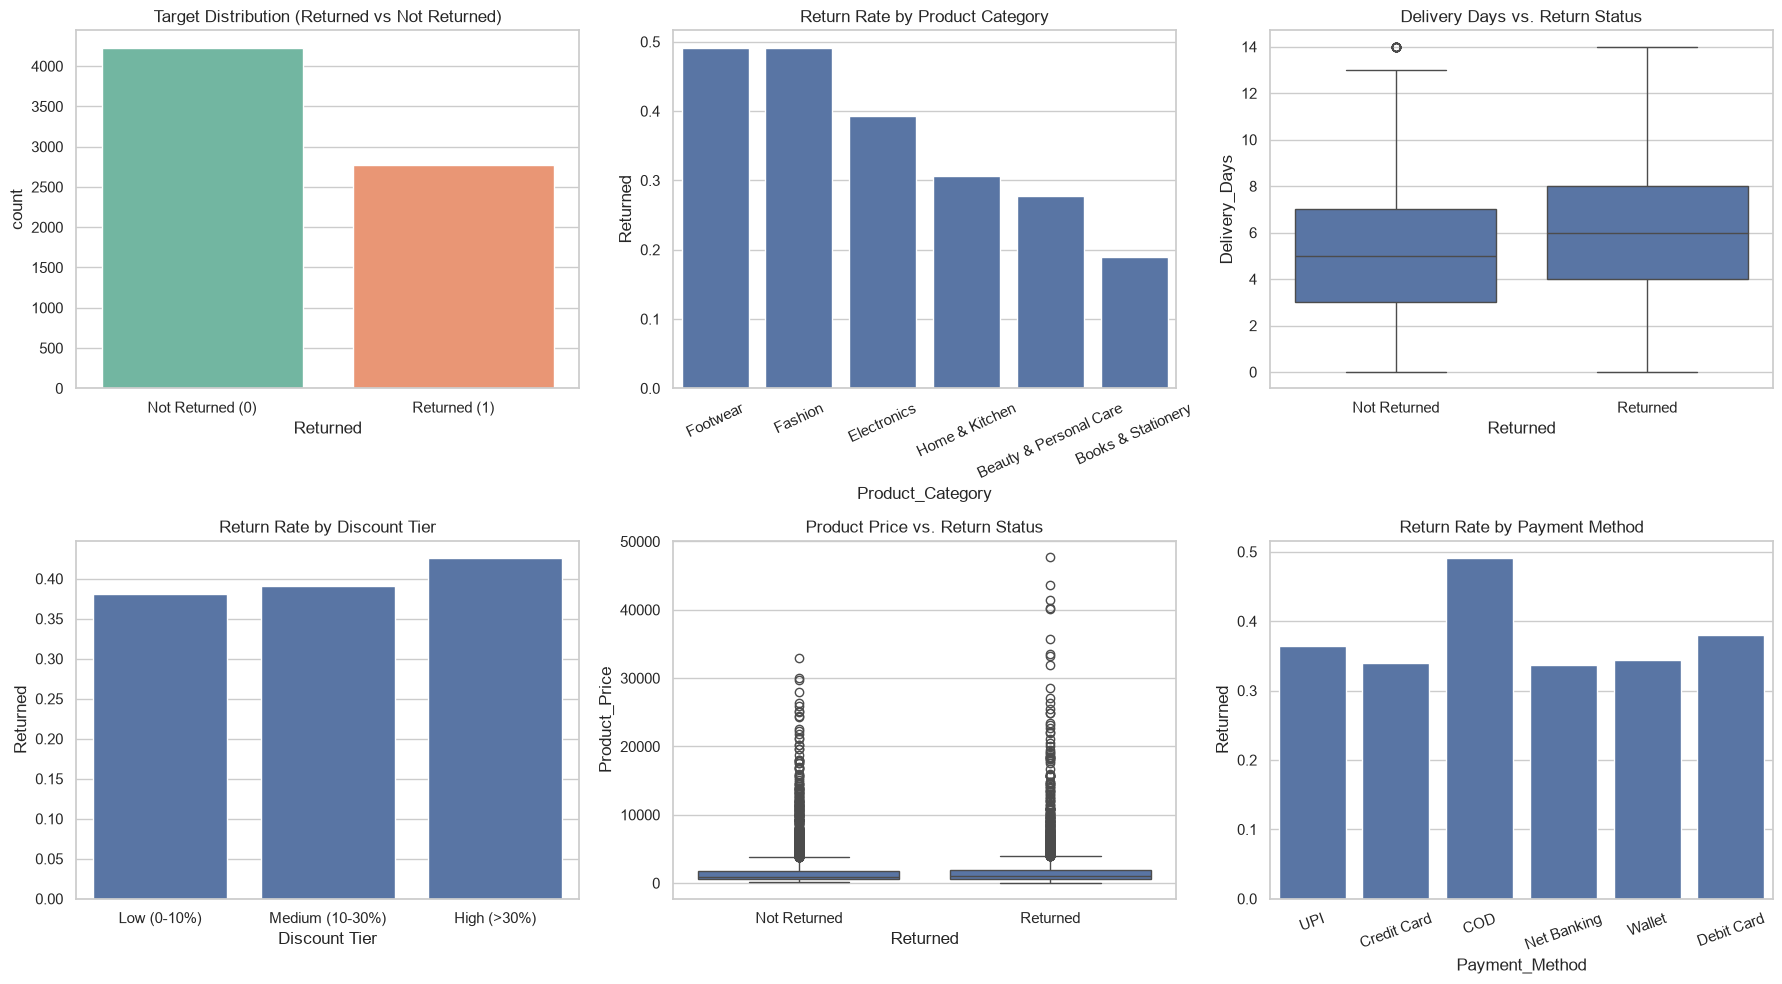

,Return_Rate,Order_Count
Product_Category,,
Footwear,0.491722,604
Fashion,0.490365,2439
Electronics,0.392323,1537
Home & Kitchen,0.305957,1108
Beauty & Personal Care,0.277492,973
Books & Stationery,0.188791,339


In [11]:
return_rate = df["Returned"].mean()
print(f"Overall Return Rate: {return_rate:.2%}")
display(df["Returned"].value_counts().rename(index={0: "Not Returned", 1: "Returned"}))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Target distribution
sns.countplot(data=df, x="Returned", ax=axes[0, 0], palette="Set2", hue="Returned", legend=False)
axes[0, 0].set_title("Target Distribution (Returned vs Not Returned)")
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(["Not Returned (0)", "Returned (1)"])

# 2. Return rate by Product Category
cat_order = df.groupby("Product_Category")["Returned"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="Product_Category", y="Returned", order=cat_order, errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("Return Rate by Product Category")
axes[0, 1].tick_params(axis="x", rotation=25)

# 3. Delivery Days distribution by Return status
sns.boxplot(data=df, x="Returned", y="Delivery_Days", ax=axes[0, 2])
axes[0, 2].set_title("Delivery Days vs. Return Status")
axes[0, 2].set_xticks([0, 1])
axes[0, 2].set_xticklabels(["Not Returned", "Returned"])

# 4. Return rate by Discount Group
discount_bins = pd.cut(
    df["Discount_Percentage"],
    bins=[-0.01, 10, 30, 100],
    labels=["Low (0-10%)", "Medium (10-30%)", "High (>30%)"],
)
sns.barplot(x=discount_bins, y=df["Returned"], errorbar=None, ax=axes[1, 0])
axes[1, 0].set_title("Return Rate by Discount Tier")
axes[1, 0].set_xlabel("Discount Tier")

# 5. Product Price distribution by Return status
sns.boxplot(data=df, x="Returned", y="Product_Price", ax=axes[1, 1])
axes[1, 1].set_title("Product Price vs. Return Status")
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(["Not Returned", "Returned"])

# 6. Return rate by Payment Method
sns.barplot(data=df, x="Payment_Method", y="Returned", errorbar=None, ax=axes[1, 2])
axes[1, 2].set_title("Return Rate by Payment Method")
axes[1, 2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

display(
    df.groupby("Product_Category", dropna=False)["Returned"]
    .agg(Return_Rate="mean", Order_Count="count")
    .sort_values("Return_Rate", ascending=False)
)

## 5. Stratified Train / Validation / Test Split

Split the dataset into three stratified partitions:
- **Train (70%)**: Fit preprocessing, feature engineering, and model parameters.
- **Validation (15%)**: Compare models and tune the classification probability threshold without touching the test set.
- **Test (15%)**: Final unbiased performance evaluation.

In [12]:
RAW_FEATURE_COLS = [
    "Product_Category",
    "Product_Price",
    "Quantity",
    "Discount_Percentage",
    "Delivery_Days",
    "Payment_Method",
    "Customer_Order_Count",
    "Previous_Return_Count",
    "Product_Rating",
    "Shipping_Type",
]

X = df[RAW_FEATURE_COLS].copy()
y = df["Returned"].copy()

# 70% Train, 30% Temp (Validation + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

# Split 30% Temp equally into 15% Validation and 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Train shape:      {X_train.shape} | Return rate: {y_train.mean():.2%}")
print(f"Validation shape: {X_val.shape} | Return rate: {y_val.mean():.2%}")
print(f"Test shape:       {X_test.shape} | Return rate: {y_test.mean():.2%}")

Train shape:      (4900, 10) | Return rate: 39.55%
Validation shape: (1050, 10) | Return rate: 39.62%
Test shape:       (1050, 10) | Return rate: 39.52%


## 6. Custom Feature Engineering & Preprocessing Pipeline

Encapsulating feature engineering inside a `scikit-learn` transformer (`OrderFeatureEngineer`) ensures that:
1. Single-order and bulk predictions only require the **10 raw input features**—derived features are computed automatically and consistently.
2. No data leakage occurs across train, validation, and test splits.

**Engineered Features:**
- `Customer_Return_Rate`: Historical return ratio (`Previous_Return_Count / Customer_Order_Count`, `0.0` for new customers).
- `Effective_Unit_Price`: Net unit price after discount (`Product_Price * (1 - Discount_Percentage / 100)`).
- `Total_Order_Value`: Net order value (`Effective_Unit_Price * Quantity`).
- `Discount_Category`: Binned discount tier (`Low`, `Medium`, `High`).
- `Customer_Type`: Binned order frequency (`New Customer`, `Regular Customer`, `Frequent Customer`).

In [13]:
class OrderFeatureEngineer(BaseEstimator, TransformerMixin):
    """Creates domain-specific e-commerce features from raw order columns."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()

        # Safe historical return rate (0 for first-time customers)
        order_count = X_out["Customer_Order_Count"].replace(0, np.nan)
        X_out["Customer_Return_Rate"] = (
            X_out["Previous_Return_Count"] / order_count
        ).fillna(0.0)

        # Monetary features accounting for discount and quantity
        discount_factor = 1.0 - (X_out["Discount_Percentage"].fillna(0.0) / 100.0)
        X_out["Effective_Unit_Price"] = X_out["Product_Price"] * discount_factor
        X_out["Total_Order_Value"] = X_out["Effective_Unit_Price"] * X_out["Quantity"]

        # Categorical tiers
        X_out["Discount_Category"] = pd.cut(
            X_out["Discount_Percentage"],
            bins=[-0.01, 10, 30, 100],
            labels=["Low", "Medium", "High"],
        ).astype("object").fillna("Missing")

        X_out["Customer_Type"] = pd.cut(
            X_out["Customer_Order_Count"],
            bins=[-1, 0, 5, np.inf],
            labels=["New Customer", "Regular Customer", "Frequent Customer"],
        ).astype("object").fillna("Missing")

        return X_out


ENGINEERED_NUMERICAL_COLS = [
    "Product_Price",
    "Quantity",
    "Discount_Percentage",
    "Delivery_Days",
    "Customer_Order_Count",
    "Previous_Return_Count",
    "Product_Rating",
    "Customer_Return_Rate",
    "Effective_Unit_Price",
    "Total_Order_Value",
]

ENGINEERED_CATEGORICAL_COLS = [
    "Product_Category",
    "Payment_Method",
    "Shipping_Type",
    "Discount_Category",
    "Customer_Type",
]


def build_preprocessor():
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder),
    ])

    return ColumnTransformer([
        ("num", numeric_pipe, ENGINEERED_NUMERICAL_COLS),
        ("cat", categorical_pipe, ENGINEERED_CATEGORICAL_COLS),
    ])

## 7. Cross-Validation & Model Comparison

Compare three distinct model families using 5-fold Stratified Cross-Validation on the training set, then fit them on the full training partition:
1. **Logistic Regression** (linear baseline with balanced class weights)
2. **Random Forest** (bagged decision trees with balanced class weights)
3. **Histogram Gradient Boosting** (gradient-boosted trees with automatic class weighting)

In [14]:
candidate_models = {
    "Logistic Regression": Pipeline([
        ("features", OrderFeatureEngineer()),
        ("preprocessor", build_preprocessor()),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("features", OrderFeatureEngineer()),
        ("preprocessor", build_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=15,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
    "HistGradientBoosting": Pipeline([
        ("features", OrderFeatureEngineer()),
        ("preprocessor", build_preprocessor()),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=250,
            learning_rate=0.05,
            max_depth=8,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, pipeline in candidate_models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={"f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"},
        n_jobs=-1,
    )
    cv_rows.append({
        "Model": name,
        "CV_F1_Mean": scores["test_f1"].mean(),
        "CV_F1_Std": scores["test_f1"].std(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean(),
        "CV_PR_AUC": scores["test_pr_auc"].mean(),
    })
    pipeline.fit(X_train, y_train)

cv_df = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV_ROC_AUC", ascending=False)
print("5-Fold Stratified Cross-Validation Results (Train Set):")
display(cv_df.style.format("{:.4f}"))

5-Fold Stratified Cross-Validation Results (Train Set):


,CV_F1_Mean,CV_F1_Std,CV_ROC_AUC,CV_PR_AUC
Model,,,,
Logistic Regression,0.5914,0.0102,0.7070,0.6074
Random Forest,0.5604,0.0081,0.6791,0.5606
HistGradientBoosting,0.5514,0.0107,0.6639,0.5478


## 8. Validation Threshold Optimization & Final Test Evaluation

Rather than relying blindly on a `0.50` cutoff, select the probability threshold on the **Validation set** that maximizes `F1-Score` (or adjust to prioritize recall/precision based on operational costs), and evaluate once on the held-out **Test set**.

In [15]:
def find_best_f1_threshold(y_true, y_prob):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    f1_scores = (2 * precisions[:-1] * recalls[:-1]) / np.maximum(
        precisions[:-1] + recalls[:-1], 1e-12
    )
    best_idx = int(np.argmax(f1_scores))
    return float(thresholds[best_idx]), float(f1_scores[best_idx])


val_summary = {}
for name, pipeline in candidate_models.items():
    val_prob = pipeline.predict_proba(X_val)[:, 1]
    opt_thresh, val_f1 = find_best_f1_threshold(y_val, val_prob)
    val_summary[name] = {
        "optimal_threshold": opt_thresh,
        "val_f1": val_f1,
        "val_roc_auc": roc_auc_score(y_val, val_prob),
        "val_pr_auc": average_precision_score(y_val, val_prob),
    }

val_df = pd.DataFrame(val_summary).T.sort_values("val_f1", ascending=False)
print("Validation Set Results & Tuned Thresholds:")
display(val_df.style.format("{:.4f}"))

# Evaluate all models on the held-out Test set using their validation-tuned thresholds
test_rows = []
test_predictions = {}

for name, pipeline in candidate_models.items():
    thresh = val_summary[name]["optimal_threshold"]
    test_prob = pipeline.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= thresh).astype(int)
    test_predictions[name] = (test_pred, test_prob, thresh)

    test_rows.append({
        "Model": name,
        "Tuned_Threshold": thresh,
        "Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F1_Score": f1_score(y_test, test_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, test_prob),
        "PR_AUC": average_precision_score(y_test, test_prob),
    })

results_df = pd.DataFrame(test_rows).set_index("Model").sort_values("F1_Score", ascending=False)
print("\nHeld-Out Test Set Performance:")
display(results_df.style.format("{:.4f}"))

Validation Set Results & Tuned Thresholds:


,optimal_threshold,val_f1,val_roc_auc,val_pr_auc
Logistic Regression,0.3906,0.6071,0.6946,0.6088
Random Forest,0.3584,0.6060,0.6812,0.5879
HistGradientBoosting,0.3631,0.6023,0.6710,0.5780



Held-Out Test Set Performance:


,Tuned_Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
Model,,,,,,,
HistGradientBoosting,0.3631,0.5733,0.4769,0.8217,0.6035,0.6902,0.6085
Logistic Regression,0.3906,0.5733,0.4768,0.8169,0.6021,0.7120,0.6559
Random Forest,0.3584,0.5429,0.4585,0.8651,0.5993,0.6935,0.6104


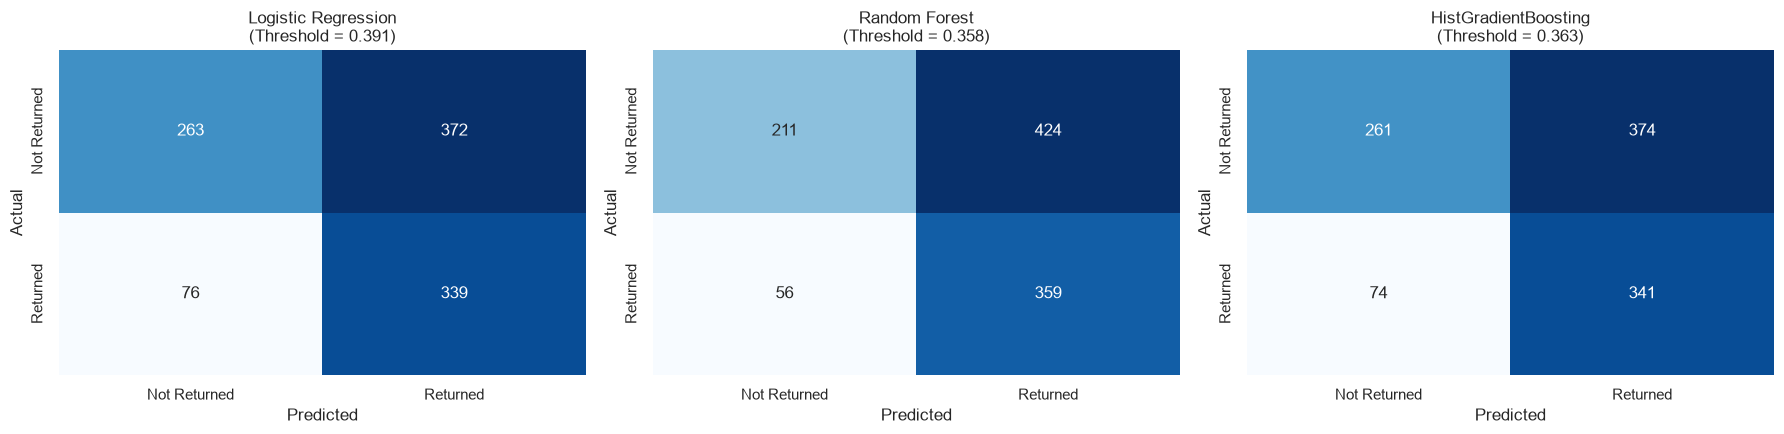

Detailed Classification Report for Selected Model: HistGradientBoosting (Threshold = 0.363)
              precision    recall  f1-score   support

Not Returned       0.78      0.41      0.54       635
    Returned       0.48      0.82      0.60       415

    accuracy                           0.57      1050
   macro avg       0.63      0.62      0.57      1050
weighted avg       0.66      0.57      0.56      1050



In [16]:
fig, axes = plt.subplots(1, len(candidate_models), figsize=(6 * len(candidate_models), 4.5))
if len(candidate_models) == 1:
    axes = [axes]

for ax, (name, (pred, prob, thresh)) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Not Returned", "Returned"],
        yticklabels=["Not Returned", "Returned"],
        ax=ax,
    )
    ax.set_title(f"{name}\n(Threshold = {thresh:.3f})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

best_model_name = results_df.index[0]
best_pred, best_prob, best_threshold = test_predictions[best_model_name]
print(f"Detailed Classification Report for Selected Model: {best_model_name} (Threshold = {best_threshold:.3f})")
print(classification_report(y_test, best_pred, target_names=["Not Returned", "Returned"], zero_division=0))

## 9. Permutation Feature Importance (Raw Input Level)

Evaluating permutation importance on the full pipeline measures how much Test `F1-Score` drops when each raw input column is shuffled.

,Feature,Importance_Mean,Importance_Std
7,Previous_Return_Count,0.040109,0.005707
0,Product_Category,0.029682,0.007573
8,Product_Rating,0.018517,0.008637
5,Payment_Method,0.017162,0.006214
3,Discount_Percentage,0.014434,0.006146
6,Customer_Order_Count,0.011757,0.006759
1,Product_Price,0.011402,0.007734
4,Delivery_Days,0.009162,0.006288
2,Quantity,0.001736,0.003824
9,Shipping_Type,-0.003974,0.001710


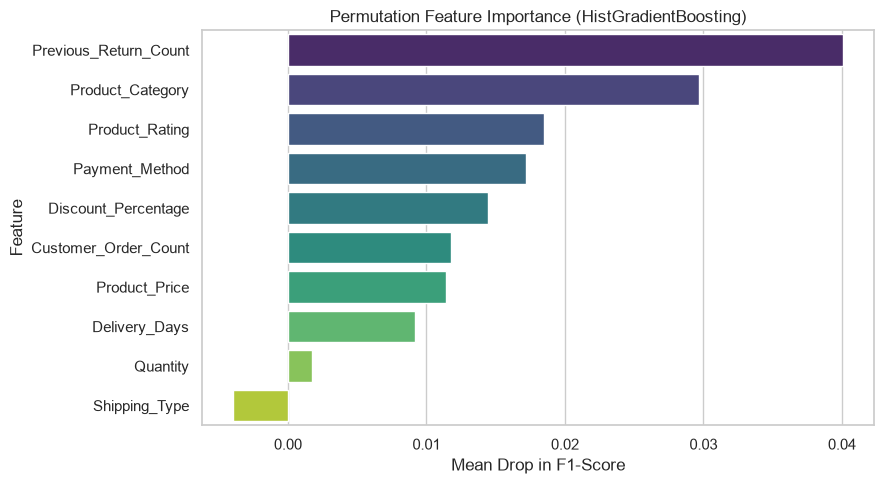

In [17]:
best_model = candidate_models[best_model_name]

def f1_with_tuned_threshold(estimator, X_eval, y_eval):
    probs = estimator.predict_proba(X_eval)[:, 1]
    preds = (probs >= best_threshold).astype(int)
    return f1_score(y_eval, preds, zero_division=0)

perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring=f1_with_tuned_threshold,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "Feature": RAW_FEATURE_COLS,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std,
}).sort_values("Importance_Mean", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df, x="Importance_Mean", y="Feature", palette="viridis", hue="Feature", legend=False)
plt.title(f"Permutation Feature Importance ({best_model_name})")
plt.xlabel("Mean Drop in F1-Score")
plt.tight_layout()
plt.show()

## 10. Save Model Pipeline & Metadata

Save the trained pipeline (including feature engineering and preprocessing), tuned threshold, and evaluation metrics to `../models/`.

In [18]:
model_path = OUTPUT_DIR / "return_prediction_model.joblib"
metadata_path = OUTPUT_DIR / "model_metadata.json"
eval_path = OUTPUT_DIR / "model_evaluation.csv"

joblib.dump(best_model, model_path)

metadata = {
    "project": "Product Return Prediction",
    "selected_model": best_model_name,
    "target": "Returned",
    "raw_features": RAW_FEATURE_COLS,
    "threshold": round(best_threshold, 4),
    "prediction_timing": "Post-delivery (uses actual Delivery_Days)",
    "data_source": DATA_SOURCE,
    "test_metrics": {
        k: round(float(v), 4) for k, v in results_df.loc[best_model_name].to_dict().items()
    },
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

results_df.to_csv(eval_path)

print(f"Saved model pipeline: {model_path}")
print(f"Saved metadata:       {metadata_path}")
print(f"Saved metrics table:  {eval_path}")

Saved model pipeline: ..\models\return_prediction_model.joblib
Saved metadata:       ..\models\model_metadata.json
Saved metrics table:  ..\models\model_evaluation.csv


## 11. Single-Order & Bulk CSV Prediction

Because `OrderFeatureEngineer` is embedded inside the saved pipeline, inference only requires the 10 raw input columns.

In [19]:
def predict_orders(input_df: pd.DataFrame, trained_model, threshold: float) -> pd.DataFrame:
    missing = [c for c in RAW_FEATURE_COLS if c not in input_df.columns]
    if missing:
        raise ValueError(f"Missing required input columns: {missing}")

    output = input_df.copy()
    probabilities = trained_model.predict_proba(output[RAW_FEATURE_COLS])[:, 1]
    output["Return_Probability"] = np.round(probabilities, 4)
    output["Predicted_Returned"] = (probabilities >= threshold).astype(int)
    output["Prediction_Label"] = output["Predicted_Returned"].map(
        {0: "Not Returned", 1: "Returned"}
    )
    return output


# Reload artifacts to verify end-to-end portability
loaded_model = joblib.load(model_path)
with open(metadata_path, "r", encoding="utf-8") as f:
    loaded_meta = json.load(f)

sample_order = pd.DataFrame([{
    "Product_Category": "Fashion",
    "Product_Price": 2500.0,
    "Quantity": 1,
    "Discount_Percentage": 25.0,
    "Delivery_Days": 7,
    "Payment_Method": "UPI",
    "Customer_Order_Count": 12,
    "Previous_Return_Count": 4,
    "Product_Rating": 3.5,
    "Shipping_Type": "Standard",
}])

sample_result = predict_orders(sample_order, loaded_model, threshold=loaded_meta["threshold"])
display(sample_result)

,Product_Category,Product_Price,Quantity,Discount_Percentage,Delivery_Days,Payment_Method,Customer_Order_Count,Previous_Return_Count,Product_Rating,Shipping_Type,Return_Probability,Predicted_Returned,Prediction_Label
0,Fashion,2500.0,1,25.0,7,UPI,12,4,3.5,Standard,0.7806,1,Returned


In [20]:
# Bulk inference example:
new_orders_path = DATA_PATH.parent / "new_orders.csv"
if new_orders_path.exists():
    new_orders = pd.read_csv(new_orders_path)
    bulk_results = predict_orders(new_orders, loaded_model, threshold=loaded_meta["threshold"])
    bulk_results.to_csv(OUTPUT_DIR / "bulk_return_predictions.csv", index=False)
    display(bulk_results.head())

,Order_ID,Product_Category,Product_Price,Quantity,Discount_Percentage,Delivery_Days,Payment_Method,Customer_Order_Count,Previous_Return_Count,Product_Rating,Shipping_Type,Return_Probability,Predicted_Returned,Prediction_Label
0,IND-ORD-200001,Footwear,789.0,3,24.8,3,Credit Card,6,1,4.2,Express,0.5033,1,Returned
1,IND-ORD-200002,Fashion,1329.0,1,7.1,3,UPI,9,1,4.1,Standard,0.2431,0,Not Returned
2,IND-ORD-200003,Beauty & Personal Care,939.0,4,8.2,3,COD,1,0,4.4,Standard,0.3801,1,Returned
3,IND-ORD-200004,Home & Kitchen,1630.0,1,34.5,12,COD,5,0,4.4,Standard,0.4978,1,Returned
4,IND-ORD-200005,Home & Kitchen,1220.0,1,34.7,4,COD,5,0,4.2,Standard,0.3912,1,Returned


## 12. Business Caveats & Production Notes

- **Pre-delivery vs. Post-delivery**: `Delivery_Days` here reflects actual delivery duration. To score orders at checkout before delivery, retrain using *estimated* delivery days instead.
- **No Post-Return Leakage**: Never include `Return_Reason`, refund status, or customer support tickets created after delivery.
- **Streamlit Integration**: When importing `return_prediction_model.joblib` inside a Streamlit app, keep `OrderFeatureEngineer` in a shared `features.py` module so `joblib.load()` can deserialize the custom transformer cleanly across scripts.